<a href="https://colab.research.google.com/github/Shivamthakur7500/FireWatchNet/blob/main/06_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, json, joblib, time, os
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
BASE = "/content/drive/MyDrive/FireWatchNet"
SEED = 42
os.makedirs(f"{BASE}/Results", exist_ok=True); os.makedirs(f"{BASE}/Models", exist_ok=True)

D = pd.read_parquet(f"{BASE}/Data/processed/firewatchnet_dataset.parquet")
D["forecast_date"] = pd.to_datetime(D["forecast_date"])
TARGET = "fire_next_7d"
FEATURES = ["prior_7d_days", "prior_30d_days", "had_detection_prior_7d", "had_detection_prior_30d",
            "cum_days_before", "x_utm", "y_utm", "lat", "lon", "doy_sin", "doy_cos",
            "temperature_2m_c", "precipitation_mm", "volumetric_soil_water_layer_1", "wind_speed",
            "precip_7d_mm", "precip_30d_mm", "temp_7d_c", "soil_7d"]
D[FEATURES] = D[FEATURES].astype("float32")
print(D.shape, "| missing feature values:", int(D[FEATURES].isna().sum().sum()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1585430, 24) | missing feature values: 0


In [ ]:
def make_xgb(pos_weight):
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=pos_weight, tree_method="hist",
                         n_jobs=-1, random_state=SEED, eval_metric="aucpr")

def make_rf(pos_weight):
    return RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=100,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)

def fit(name, maker, df):
    if name == "RandomForest" and len(df) > 300_000:      # subsample for speed (fixed seed)
        df = df.sample(300_000, random_state=SEED)
    y = df[TARGET]
    m = maker((y == 0).sum() / max((y == 1).sum(), 1))
    m.fit(df[FEATURES], y)
    return m

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.argmax(f1)])

def run(name, maker, tr, te):
    vstart = tr.forecast_date.max() - pd.Timedelta(days=29)
    inner_tr = tr[tr.forecast_date < vstart - pd.Timedelta(days=7)]   # 7-day gap, no label overlap
    inner_va = tr[tr.forecast_date >= vstart]
    m = fit(name, maker, inner_tr)
    thr = best_threshold(inner_va[TARGET], m.predict_proba(inner_va[FEATURES])[:, 1])
    m = fit(name, maker, tr)                                          # refit on full training window
    return m, thr, m.predict_proba(te[FEATURES])[:, 1]

def metrics(name, ev, y, score, pred, thr=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"evaluation": ev[:2], "model": name, "base_rate": y.mean(),
            "PR_AUC": average_precision_score(y, score), "ROC_AUC": roc_auc_score(y, score),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn, "threshold": thr}
print("functions ready")

functions ready


In [ ]:
EVALS = {
 "E1: train 2023 -> test Jan-Jun 2024": (D[D.split == "train"], D[D.split == "val"]),
 "E2: train 2023-Jun 2024 -> test Jul-Dec 2024": (D[D.split.isin(["train", "val"])], D[D.split == "test"]),
}
rows, models = [], {}
for ev, (tr, te) in EVALS.items():
    y = te[TARGET].to_numpy()
    out = te[["cell_id", "forecast_date", TARGET]].copy()
    rows.append(metrics("Persistence baseline", ev, y, te.prior_7d_days.to_numpy(),
                        te.had_detection_prior_7d.to_numpy().astype(int)))
    for name, maker in [("XGBoost", make_xgb), ("RandomForest", make_rf)]:
        t0 = time.time()
        m, thr, p = run(name, maker, tr, te)
        rows.append(metrics(name, ev, y, p, (p >= thr).astype(int), thr))
        out["p_" + name] = p
        models[(ev[:2], name)] = (m, thr)
        print(f"{ev[:2]} {name} done in {time.time()-t0:.0f}s")
    out.to_parquet(f"{BASE}/Data/processed/predictions_{ev[:2]}.parquet", index=False)

R = pd.DataFrame(rows)
R.to_csv(f"{BASE}/Results/model_metrics.csv", index=False)
pd.set_option("display.width", 250)
print(R.round(4).to_string(index=False))

m, thr = models[("E2", "XGBoost")]
joblib.dump({"model": m, "threshold": thr, "features": FEATURES, "seed": SEED,
             "note": "XGBoost baseline, trained 2023-01-01..2024-06-23, 5km grid, target fire in next 7 days"},
            f"{BASE}/Models/firewatchnet_model.pkl")
print("saved model and metrics")

E1 XGBoost done in 43s
E1 RandomForest done in 66s
E2 XGBoost done in 48s
E2 RandomForest done in 71s
evaluation                model  base_rate  PR_AUC  ROC_AUC  precision  recall     F1    TP    FP    FN     TN  threshold
        E1 Persistence baseline     0.0978  0.2041   0.6411     0.3444  0.3503 0.3473 13388 25484 24829 327074        NaN
        E1              XGBoost     0.0978  0.1972   0.7397     0.2225  0.2713 0.2445 10368 36223 27849 316335     0.6948
        E1         RandomForest     0.0978  0.3089   0.7895     0.2299  0.6449 0.3390 24645 82552 13572 270006     0.5757
        E2 Persistence baseline     0.0095  0.1023   0.6255     0.2951  0.2566 0.2745   966  2308  2799 389168        NaN
        E2              XGBoost     0.0095  0.2092   0.9418     0.1151  0.6205 0.1941  2336 17968  1429 373508     0.4945
        E2         RandomForest     0.0095  0.2332   0.9450     0.1715  0.5033 0.2558  1895  9154  1870 382322     0.5669
saved model and metrics


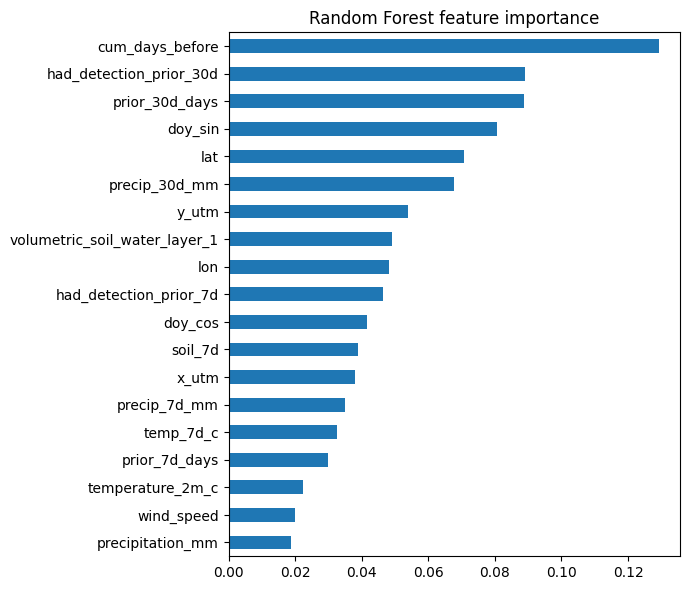

cum_days_before                  0.129
had_detection_prior_30d          0.089
prior_30d_days                   0.089
doy_sin                          0.081
lat                              0.071
precip_30d_mm                    0.068
y_utm                            0.054
volumetric_soil_water_layer_1    0.049
dtype: float64


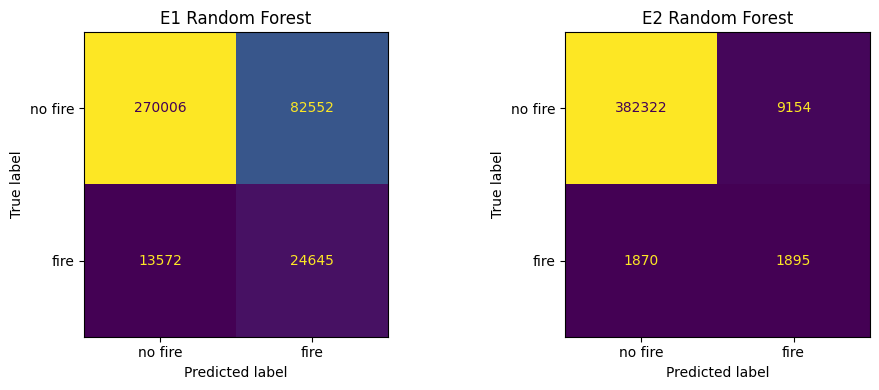

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

m, thr = models[("E2", "RandomForest")]
joblib.dump({"model": m, "threshold": thr, "features": FEATURES, "seed": SEED,
             "note": "RandomForest baseline (NOT a ViT-GNN hybrid), trained 2023-01-01..2024-06-23 on a "
                     "300k-row sample, 5km grid, target: fire detected in next 7 days"},
            f"{BASE}/Models/firewatchnet_model.pkl")

imp = pd.Series(m.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax); ax.set_title("Random Forest feature importance")
plt.tight_layout(); plt.savefig(f"{BASE}/Results/feature_importance.png", dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(3).head(8))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, ev in zip(axs, ["E1", "E2"]):
    r = R[(R.evaluation == ev) & (R.model == "RandomForest")].iloc[0]
    cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
    ConfusionMatrixDisplay(cm, display_labels=["no fire", "fire"]).plot(ax=ax, values_format=".0f", colorbar=False)
    ax.set_title(f"{ev} Random Forest")
plt.tight_layout(); plt.savefig(f"{BASE}/Results/confusion_matrix.png", dpi=150); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np
BASE = "/content/drive/MyDrive/FireWatchNet"
bins = [0, .1, .2, .3, .4, .5, .6, .7, .8, 1.0001]
for ev in ["E1", "E2"]:
    df = pd.read_parquet(f"{BASE}/Data/processed/predictions_{ev}.parquet")
    df["score_bin"] = pd.cut(df["p_RandomForest"], bins, right=False)
    t = df.groupby("score_bin", observed=True).agg(cell_days=("fire_next_7d", "size"),
                                                   fire_rate=("fire_next_7d", "mean")).round(4)
    print(f"\n{ev}  overall fire rate = {df['fire_next_7d'].mean():.4f}")
    print(t)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

E1  overall fire rate = 0.0978
            cell_days  fire_rate
score_bin                       
[0.0, 0.1)      74138     0.0016
[0.1, 0.2)      34928     0.0204
[0.2, 0.3)      37519     0.0577
[0.3, 0.4)      39901     0.0473
[0.4, 0.5)      50859     0.0719
[0.5, 0.6)      59745     0.1204
[0.6, 0.7)      46093     0.1633
[0.7, 0.8)      29989     0.2391
[0.8, 1.0)      17603     0.4427

E2  overall fire rate = 0.0095
            cell_days  fire_rate
score_bin                       
[0.0, 0.1)     278271     0.0003
[0.1, 0.2)      47273     0.0036
[0.2, 0.3)      22406     0.0141
[0.3, 0.4)      16603     0.0246
[0.4, 0.5)      13641     0.0420
[0.5, 0.6)       7689     0.0537
[0.6, 0.7)       5176     0.1291
[0.7, 0.8)       2786     0.2146
[0.8, 1.0)       1396     0.3897
